# cb_2020_12_tract_500k.zip

Executed source EDA. Only aggregate outputs are retained. Public inputs remain local. No causal inference or attendance model is used.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'public/data/manifest.json').exists())
manifest = json.loads((ROOT/'public/data/manifest.json').read_text())
areas = pd.read_json(ROOT/'public/data/areas.json')
counties = {c + ' County' for c in manifest['geography']}
print('Mode:', manifest['mode'], '| Version:', manifest['datasetVersion'])


Mode: observed | Version: 5d7db3d37ab5


Source CRS: NAD83


Matched tracts: 490 | Invalid: 0


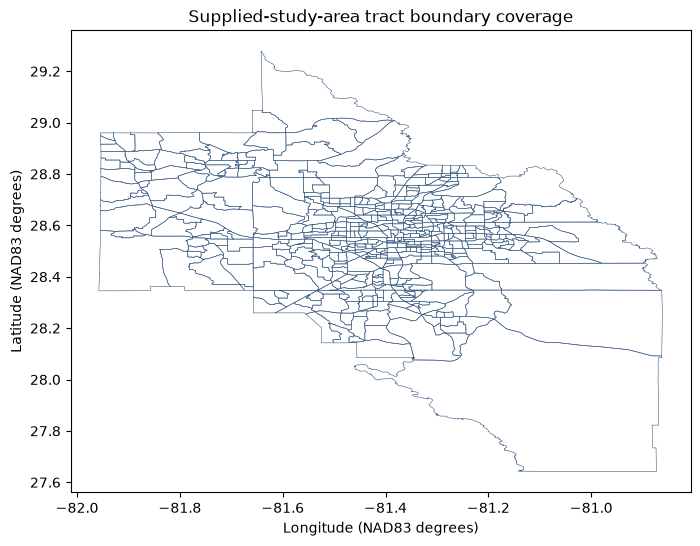

In [2]:
import shapefile
from zipfile import ZipFile
from shapely.geometry import shape
from pyproj import CRS
with ZipFile(ROOT/'data/raw/cb_2020_12_tract_500k.zip') as archive:
    prj = next(n for n in archive.namelist() if n.endswith('.prj'))
    print('Source CRS:', CRS.from_wkt(archive.read(prj).decode()).name)
with shapefile.Reader(str(ROOT/'data/raw/cb_2020_12_tract_500k.zip')) as reader:
    geometries = [shape(r.shape.__geo_interface__) for r in reader.iterShapeRecords() if r.record.as_dict()['GEOID'] in set(areas.id.astype(str))]
print('Matched tracts:', len(geometries), '| Invalid:', sum(not g.is_valid for g in geometries))
fig, ax = plt.subplots(figsize=(8,6))
for g in geometries:
    parts = list(g.geoms) if g.geom_type == 'MultiPolygon' else [g]
    for part in parts:
        x, y = part.exterior.xy
        ax.plot(x,y,linewidth=.4,color='#385981')
ax.set(xlabel='Longitude (NAD83 degrees)', ylabel='Latitude (NAD83 degrees)', title='Supplied-study-area tract boundary coverage')
plt.show()


## Interpretation and limitations

The displayed row counts and missingness are observed from these local files. Numeric outliers are retained unless a documented source error exists. Statistical geography is the census tract; retailer locations are points, not service coverage. Estimates have mixed vintages and cannot establish individual need, travel time, attendance, or causal impact. ACS poverty/SNAP sentinel values remain missing. Tract-level associations do not describe individual households. The 2020 geometry joins by exact GEOID, never by tract label. See `docs/data_audit.md` and `docs/transformations.md` for exclusions and lineage.